In [1]:
import os
# os.environ['CUDA_VISIBLE_DEVICES']='1'

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import pickle

import jax
import jax.numpy as jnp
from tqdm import tqdm
import optax
import flax.linen as nn
from flax.metrics import tensorboard
from jax_resnet import resnet
from functools import partial

# import datasets
# import tensorflow_datasets as tfds

In [2]:
# Define folders
SHEAR2COSMO_dir = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/deeplh1/"
IMAGESIMS_dir = SHEAR2COSMO_dir + "tensorflow_datasets/"
LOGS_dir = SHEAR2COSMO_dir + "logs/"
MODELS_dir = SHEAR2COSMO_dir + "MODELS/"
PLOTS_dir = SHEAR2COSMO_dir + "PLOTS/"

In [3]:
# Define hyperparameters and suffix
batch_size = 64
N_maps = 2600 * 4
epochs = 200

# Define a scheduler for the learning rate
total_steps = int(epochs * N_maps / batch_size)

lri = 0.001

lr2 = 0.3  # 0.3
step_2 = total_steps * 0.1
step_2_ep = int(step_2 * batch_size / N_maps)

print("total steps=", total_steps)
# print("step_2=",step_2)

lr_scheduler = optax.piecewise_constant_schedule(
    init_value=lri,
    boundaries_and_scales={
        int(step_2): lr2,
    },
)
"""
init_value = 2e-3
nb_batch_train = 2600*5*0.6/batch_size

lr_scheduler = optax.piecewise_constant_schedule( init_value=init_value,
    boundaries_and_scales={
        int(nb_batch_train * 40): 0.5,
        int(nb_batch_train * 80): 0.66,
        int(nb_batch_train * 120): 0.66,
    },)
"""

loss_func = "MSE"


# Define a simple MSE regression loss
def loss_fn(params, batch):
    return jnp.mean(jnp.sum((model.apply(params, batch["x"]) - batch["y"]) ** 2, axis=-1))


case = (
    "cosmoslics_resnet18_loss"
    + loss_func
    + "_norm_1"
    + "_Nmaps"
    + str(N_maps)
    + "_lri"
    + str(lri)
    + "_lr2"
    + str(lr2)
    + "_step2_"
    + str(step_2_ep)
    + "_batch"
    + str(batch_size)
    + "_epochs"
    + str(epochs)
)
# case = 'cosmoslics_resnet18_loss'+loss_func+'norm_1'+'_Nmaps'+str(N_maps)+'_lri'+str(init_value)+'_lrsteps'+str(3)+'_batch'+str(batch_size)+'_epochs'+str(epochs)
print(case)

total steps= 32500
cosmoslics_resnet18_lossMSE_norm_1_Nmaps10400_lri0.001_lr20.3_step2_20_batch64_epochs200


In [4]:
"""class DataLoader:
    def init(
        self,
        dir_path,
        batch_size,
        mean_images,
        std_images,
        min_images,
        max_images,
        min_params,
        max_params,
        normalisation,
        shear_bounds,
        shuffle,
    ):
        self.dir_path = dir_path
        self.batch_size = batch_size
        self.min_images = min_images
        self.max_images = max_images
        self.mean_images = mean_images
        self.std_images = std_images
        self.min_shears = min_shears
        self.max_shears = max_shears
        self.normalisation = normalisation
        self.shear_bounds = shear_bounds
        self.shuffle = shuffle
    self.image_files = sorted(self.dir_path.glob("simu_*.fits"))
    self.shear_files = sorted(self.dir_path.glob("shear_*.fits"))
    self.indices = numpy.arange(len(self.image_files))
    assert len(self.image_files) == len(self.shear_files)

# load *.fits file
@staticmethod
def load_fits(file):
    with fits.open(file) as hdul:
        img = hdul[0].data
    return img

@staticmethod
def min_max(x, mini, maxi, inf=0, sup=1):
    return (sup - inf) * (x - mini) / (maxi - mini) + inf

@staticmethod
def sigmoid(x):
    scale = 5
    return 1 / (1 + jax.numpy.exp(-scale * (x - 0.5)))

@staticmethod
def streching(x):
    power = 1 / 3
    return jax.numpy.power(x, power)

@staticmethod
def logy(x):
    scale = 10
    return jax.numpy.log1p(x * scale)

@staticmethod
def range_compression(x):
    return jax.numpy.arcsinh(x / 3)

def load_batch_data(self, batch_indices, data_files):
    return jax.numpy.array([self.load_fits(data_files[idx]) for idx in batch_indices])

def mean_std(self, x):
    return (x - self.mean_images) / self.std_images

def generate(self):
    # randomises data sent by dataloader
    if self.shuffle:
        key_shuffle = jax.random.PRNGKey(seed=int(time() * 1e6))
        self.indices = jax.random.permutation(key=key_shuffle, x=self.indices)

    for i in range(0, len(self.image_files), self.batch_size):
        batch_indices = self.indices[i : i + self.batch_size]

        # load images and shears
        x = self.load_batch_data(batch_indices, self.image_files)
        y = self.load_batch_data(batch_indices, self.shear_files)

        # images normalisation
        if self.normalisation == "sigmoid":
            x = self.min_max(x, mini=self.min_images, maxi=self.max_images)
            x = self.sigmoid(x)
        elif self.normalisation == "streching":
            x = self.min_max(x, mini=self.min_images, maxi=self.max_images)
            x = self.streching(x)
        elif self.normalisation == "compress":
            x = self.mean_std(x)
            x = self.range_compression(x)
        elif self.normalisation == "logy":
            x = self.min_max(x, mini=self.min_images, maxi=self.max_images)
            x = self.logy(x)

        # shear normalisation
        y = self.min_max(
            y,
            mini=self.min_shears,
            maxi=self.max_shears,
            inf=self.shear_bounds[0],
            sup=self.shear_bounds[1],
        )

        yield jax.numpy.expand_dims(x, axis=-1), jax.numpy.array(y)"""

'class DataLoader:\n    def init(\n        self,\n        dir_path,\n        batch_size,\n        mean_images,\n        std_images,\n        min_images,\n        max_images,\n        min_params,\n        max_params,\n        normalisation,\n        shear_bounds,\n        shuffle,\n    ):\n        self.dir_path = dir_path\n        self.batch_size = batch_size\n        self.min_images = min_images\n        self.max_images = max_images\n        self.mean_images = mean_images\n        self.std_images = std_images\n        self.min_shears = min_shears\n        self.max_shears = max_shears\n        self.normalisation = normalisation\n        self.shear_bounds = shear_bounds\n        self.shuffle = shuffle\n    self.image_files = sorted(self.dir_path.glob("simu_*.fits"))\n    self.shear_files = sorted(self.dir_path.glob("shear_*.fits"))\n    self.indices = numpy.arange(len(self.image_files))\n    assert len(self.image_files) == len(self.shear_files)\n\n# load *.fits file\n@staticmethod\ndef l

In [6]:
class DataLoader:
    def __init__(
        self,
        dir_path_image,
        dir_path_params,
        input_file_path,
        batch_size,
        mean_images,
        std_images,
        min_images,
        max_images,
        min_params,
        max_params,
        normalisation,
        params_bounds,
        shuffle,
        train_ratio=0.6,
        val_ratio=0.2,
        test_ratio=0.2,
    ):
        self.dir_path_image = Path(dir_path_image)
        self.dir_path_params = Path(dir_path_params)
        self.input_file_path = input_file_path
        self.batch_size = batch_size
        self.min_images = min_images
        self.max_images = max_images
        self.mean_images = mean_images
        self.std_images = std_images
        self.min_params = min_params
        self.max_params = max_params
        self.normalisation = normalisation
        self.params_bounds = params_bounds
        self.shuffle = shuffle

        self.image_files = sorted(self.dir_path_image.glob("glass_*.npy"))
        self.params_files = sorted(self.dir_path_params.glob("cosmoslics_id*.dat"))
        self.indices = np.arange(len(self.image_files))
        assert len(self.image_files) == len(self.params_files)

        # Split data
        assert train_ratio + val_ratio + test_ratio == 1.0, "Les ratios doivent totaliser 1."
        total_count = len(self.indices)
        train_end = int(total_count * train_ratio)
        val_end = train_end + int(total_count * val_ratio)

        self.train_indices = self.indices[:train_end]
        self.val_indices = self.indices[train_end:val_end]
        self.test_indices = self.indices[val_end:]

    # load *.npy file
    @staticmethod
    def load_npy(file):
        return np.load(file)

    @staticmethod
    def load_txt(file):
        return np.loadtxt(file)

    @staticmethod
    def min_max(x, mini, maxi, inf=0, sup=1):
        return (sup - inf) * (x - mini) / (maxi - mini) + inf

    @staticmethod
    def sigmoid(x):
        scale = 5
        return 1 / (1 + jnp.exp(-scale * (x - 0.5)))

    @staticmethod
    def streching(x):
        power = 1 / 3
        return jnp.power(x, power)

    @staticmethod
    def logy(x):
        scale = 10
        return jnp.log1p(x * scale)

    @staticmethod
    def range_compression(x):
        return jnp.arcsinh(x / 3)

    def load_batch_data(self, batch_indices, data_files):
        if data_files == self.image_files:
            return jnp.array([self.load_npy(data_files[idx]) for idx in batch_indices])
        if data_files == self.params_files:
            return jnp.array([self.load_txt(data_files[idx]) for idx in batch_indices])

    def mean_std(self, x):
        return (x - self.mean_images) / self.std_images

    def generate(self, dataset):
        if dataset == "train":
            self.indices = self.train_indices
        elif dataset == "val":
            self.indices = self.val_indices
        elif dataset == "test":
            self.indices = self.test_indices
        # randomises data sent by dataloader
        if self.shuffle:
            key_shuffle = jax.random.PRNGKey(seed=int(np.random.randint(0, 1e6)))
            self.indices = jax.random.permutation(key=key_shuffle, x=self.indices)

        for i in range(0, len(self.indices), self.batch_size):
            batch_indices = self.indices[i : i + self.batch_size]

            # load images
            x = self.load_batch_data(batch_indices, self.image_files)
            y = self.load_batch_data(batch_indices, self.params_files)

            # images normalisation
            if self.normalisation == "sigmoid":
                x = self.min_max(x, mini=self.min_images, maxi=self.max_images)
                x = self.sigmoid(x)
            elif self.normalisation == "streching":
                x = self.min_max(x, mini=self.min_images, maxi=self.max_images)
                x = self.streching(x)
            elif self.normalisation == "compress":
                x = self.mean_std(x)
                x = self.range_compression(x)
            elif self.normalisation == "logy":
                x = self.min_max(x, mini=self.min_images, maxi=self.max_images)
                x = self.logy(x)

            # params normalisation
            y = self.min_max(
                y,
                mini=self.min_params,
                maxi=self.max_params,
                inf=self.params_bounds[0],
                sup=self.params_bounds[1],
            )

            yield jax.numpy.expand_dims(x, axis=-1), jax.numpy.array(y)

    def verify_data(self):
        print("Number of image files:", len(self.image_files))
        print("Number of params files:", len(self.params_files))

        # Load a single batch
        batch_indices = self.indices[: self.batch_size]
        x = self.load_batch_data(batch_indices, self.image_files)
        y = self.load_batch_data(batch_indices, self.params_files)

        print("Shape of a batch of images:", x.shape)
        print("Shape of a batch of params:", y.shape)

        # statistics
        print("Image batch statistics:")
        print("- Mean:", jnp.mean(x))
        print("- Std:", jnp.std(x))
        print("- Min:", jnp.min(x))
        print("- Max:", jnp.max(x))

        print("Params batch statistics:")
        print("- Mean:", jnp.mean(y))
        print("- Std:", jnp.std(y))
        print("- Min:", jnp.min(y))
        print("- Max:", jnp.max(y))

In [7]:
dir_path_image = (
    "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/data/GLASS_maps/spherical_to_cartesian/"
)
dir_path_params = "/net/GECO/pisco/SHEAR2COSMO/Leo_COSMO-SLICS/data/cosmo_slics_table"
batch_size = 64
mean_images = 0
std_images = 0.01
min_images = -0.06
max_images = 0.07
min_params = -1.9866
max_params = 0.8986
normalisation = "sigmoid"  # "sigmoid", "streching", "compress", "logy"
params_bounds = [-2, 0.9]
shuffle = True


data_loader = DataLoader(
    dir_path_image=dir_path_image,
    dir_path_params=dir_path_params,
    input_file_path=None,  # Non utilisé
    batch_size=batch_size,
    mean_images=mean_images,
    std_images=std_images,
    min_images=min_images,
    max_images=max_images,
    min_params=min_params,
    max_params=max_params,
    normalisation=normalisation,
    params_bounds=params_bounds,
    shuffle=shuffle,
)

for x, y in data_loader.generate(dataset="train"):
    print("Batch d'entraînement:")
    print("x shape:", x.shape)
    print("y shape:", y.shape)
    break

for x, y in data_loader.generate(dataset="val"):
    print("Batch de validation:")
    print("x shape:", x.shape)
    print("y shape:", y.shape)
    break

for x, y in data_loader.generate(dataset="test"):
    print("Batch de test:")
    print("x shape:", x.shape)
    print("y shape:", y.shape)
    break

train_count = len(data_loader.train_indices)
val_count = len(data_loader.val_indices)
test_count = len(data_loader.test_indices)

print("train : ", train_count)
print("validation : ", val_count)
print("test : ", test_count)
print(data_loader.train_indices)

Batch d'entraînement:
x shape: (64, 128, 128, 1)
y shape: (64, 4)
Batch de validation:
x shape: (64, 128, 128, 1)
y shape: (64, 4)
Batch de test:
x shape: (64, 128, 128, 1)
y shape: (64, 4)
train :  7800
validation :  2600
test :  2600
[   0    1    2 ... 7797 7798 7799]


In [8]:
data_loader.verify_data()

Number of image files: 13000
Number of params files: 13000
Shape of a batch of images: (64, 128, 128)
Shape of a batch of params: (64, 4)
Image batch statistics:
- Mean: 0.00014185102
- Std: 0.012782983
- Min: -0.0669449
- Max: 0.06657343
Params batch statistics:
- Mean: 0.10366365
- Std: 0.9069885
- Min: -1.8784
- Max: 0.8031


In [9]:
# Define our compressor
ResNet = partial(resnet.ResNet18, n_classes=4)


class NeuralCompressor(nn.Module):
    @nn.compact
    def __call__(self, x):
        return ResNet()(x)

In [10]:
# Random seed for sampling from posterior
seed = jax.random.PRNGKey(0)

# Let's instantiate and initialize the model
model = NeuralCompressor()
params = model.init(jax.random.PRNGKey(42), jnp.zeros(shape=[1, 128, 128, 1]))

# Initializes an optimizer and optimizer state
optimizer = optax.adam(learning_rate=lr_scheduler)
opt_state = optimizer.init(params)


#####################################
# summary_writer = tensorboard.SummaryWriter(LOGS_dir+case)
#####################################

In [10]:
cutouts = []
specz = []

# Generate batches of data using DataLoader
for x, y in data_loader.generate("train"):
    cutouts.append(x)
    specz.append(y)

# Stack the batches to get the complete dataset
cutouts = np.vstack(cutouts)
specz = np.vstack(specz)

In [11]:
print(np.shape(cutouts))

(7800, 128, 128, 1)


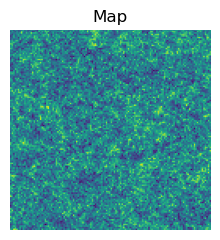

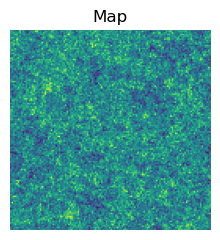

In [12]:
plt.figure(figsize=(15, 3))
for i, b in enumerate(["Map"]):
    plt.subplot(1, 5, i + 1)
    plt.imshow(cutouts[0, :, :])  # ,vmin=-4,vmax=8
    plt.title(b)
    plt.axis("off")

plt.figure(figsize=(15, 3))
for i, b in enumerate(["Map"]):
    plt.subplot(1, 5, i + 1)
    plt.imshow(cutouts[1, :, :])  # ,vmin=-4,vmax=8
    plt.title(b)
    plt.axis("off")

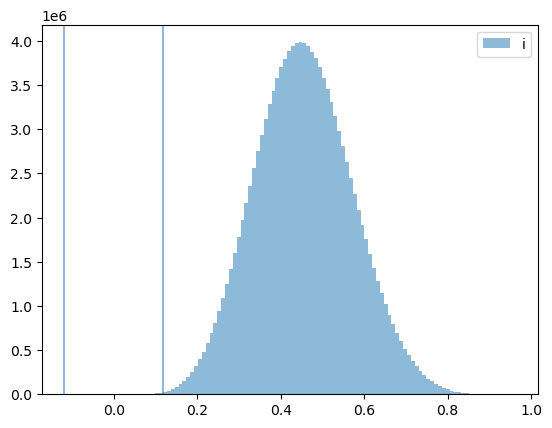

In [13]:
# Let's evaluate the noise standard deviation in each band, and apply range
# compression accordingly

from astropy.stats import mad_std

scaling = []

for i, b in enumerate(["i"]):
    plt.hist(
        cutouts[...].flatten(),
        100,
        label=b,
        alpha=0.5,
    )
    sigma = mad_std(cutouts[...].flatten())
    scaling.append(sigma)
    plt.axvline(sigma, color="C%d" % i, alpha=0.5)
    plt.axvline(-sigma, color="C%d" % i, alpha=0.5)
plt.legend()

0.034768518


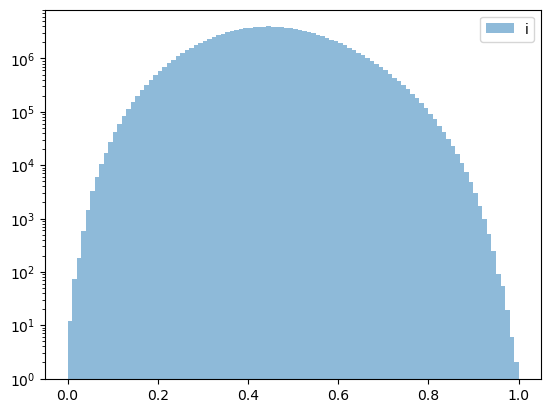

In [14]:
# Let's have a look at this distribution if we rescale it between 0 and 1 using max and min SNR values
# over the dataset and center it

min_Mapmap = np.min(cutouts[...].flatten())
max_Mapmap = np.max(cutouts[...].flatten())

for i, b in enumerate(["i"]):
    # plt.hist(cutouts[...].flatten()/scaling[i],100, label=b,alpha=0.5,
    plt.hist(
        (cutouts[...].flatten() - min_Mapmap) / (max_Mapmap - min_Mapmap),
        100,
        label=b,
        alpha=0.5,
        range=[0, 1],
    )
plt.legend()
plt.yscale("log")

print(min_Mapmap)

In [15]:
# a common approach for range compression is to apply arcsinh to suppress the
# high amplitude values
# for i,b in enumerate(['i']):
#  plt.hist(np.arcsinh(cutouts[...].flatten()/scaling[i]/3),100,
#           label=b, alpha=0.5,
#           range=[-5,5]);
# plt.legend()
# plt.yscale('log')

In [16]:
# we can have a look at individual postage stamps with or without this scaling
# plt.subplot(121)
# plt.imshow(cutouts[0,:,:]/scaling[0])
# plt.title('Before')
# plt.subplot(122)
# plt.imshow(np.arcsinh(cutouts[0,:,:]/scaling[0]/3))
# plt.title('After');

In [17]:
import tensorflow as tf


def preprocessing(example):
    def range_compression(img):
        # return tf.clip_by_value(tf.math.asinh(tf.expand_dims(img, axis=-1) / tf.constant(scaling) / 3. ),-10,10)
        return tf.clip_by_value(
            (tf.expand_dims(img, axis=-1) - min_Mapmap) / (max_Mapmap - min_Mapmap), -10, 10
        )

    # Our preprocessing function only returns the postage stamps, and the shear
    return range_compression(example["Map"]), example["CP"]

In [18]:
# batch_size = 64

"""# Load the data
dset = tfds.load('cosmo_slics',split='train[:60%]',data_dir=IMAGESIMS_dir)
dset = dset.repeat()
dset = dset.shuffle(5000)
dset = dset.map(preprocessing)
dset = dset.batch(batch_size, drop_remainder=True)
dset = dset.prefetch(-1)
dset = dset.as_numpy_iterator()"""

"""x_train = []
y_train = []

for x, y in data_loader.generate(dataset="train"):
    x_train.append(x)
    y_train.append(y)

x_train = np.vstack(x_train)
y_train = np.vstack(y_train)"""

'x_train = []\ny_train = []\n\nfor x, y in data_loader.generate(dataset="train"):\n    x_train.append(x)\n    y_train.append(y)\n\nx_train = np.vstack(x_train)\ny_train = np.vstack(y_train)'

In [19]:
"""
dset_val = tfds.load('cosmo_slics',split='train[60%:80%]',data_dir=IMAGESIMS_dir)
dset_val = dset_val.repeat()
dset_val = dset_val.map(preprocessing)
dset_val = dset_val.batch(batch_size, drop_remainder=True)
dset_val = dset_val.prefetch(-1)
dset_val = dset_val.as_numpy_iterator()"""

"\ndset_val = tfds.load('cosmo_slics',split='train[60%:80%]',data_dir=IMAGESIMS_dir)\ndset_val = dset_val.repeat()\ndset_val = dset_val.map(preprocessing)\ndset_val = dset_val.batch(batch_size, drop_remainder=True)\ndset_val = dset_val.prefetch(-1)\ndset_val = dset_val.as_numpy_iterator()"

In [20]:
@jax.jit
def update_model(params, opt_state, batch):
    # Computes the gradients of the model
    loss, grads = jax.value_and_grad(loss_fn)(params, batch)

    # Computes the weights updates and apply them
    updates, opt_state = optimizer.update(grads, opt_state)
    params = optax.apply_updates(params, updates)

    return params, opt_state, loss

In [21]:
os.environ["TENSORBOARD_BINARY"] = "/home/lburon/micromamba/envs/SHEAR2COSMO/bin/tensorboard"
%load_ext tensorboard
%tensorboard --logdir={LOGS_dir}

In [22]:
# batch = {'x': jnp.nan_to_num(batch[0]), 'y': batch[1]}  #NaN to 0

In [23]:
def plot_predictions(images, true_params, pred_params):
    param_names = [r"$\Omega_m$", r"$S_8$", r"$h$", r"$w_0$"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    for i, ax in enumerate(axes.flatten()):
        ax.scatter(true_params[:, i], pred_params[:, i], alpha=0.5, label="Predicted vs True")
        t = np.linspace(min(true_params[:, i]), max(true_params[:, i]), 100)

        # Ideal line y = x
        ax.plot(t, t, color="k", label="Ideal y=x")

        # Linear regression line
        poly = np.polyfit(true_params[:, i], pred_params[:, i], 1)
        ax.plot(
            t, poly[1] + poly[0] * t, color="r", label=f"Fit: y = {poly[0]:.2f}x + {poly[1]:.2f}"
        )

        # Formatting the plot
        ax.set_xlabel("True")
        ax.set_ylabel("Predicted")
        ax.set_title(f"{param_names[i]}: Pred vs True")
        ax.legend()

    plt.tight_layout()
    plt.show()
    plt.close()


def plot_in_out(images, true_params, pred_params):
    param_names = ["Om", "S8", "h", "w0"]
    n_images = 4
    images = images[:n_images]
    true_params = true_params[:n_images]
    pred_params = pred_params[:n_images]

    for i in range(n_images):
        plt.imshow(images[i, :, :, 0], cmap="bwr", origin="lower")
        plt.title(f"Input Image {i+1}")
        plt.axis("off")
        plt.show()

        true_str = ", ".join([f"{param_names[j]}= {true_params[i, j]:.4f}" for j in range(4)])
        pred_str = ", ".join([f"{param_names[j]}= {pred_params[i, j]:.4f}" for j in range(4)])

        print(f"True Parameters for Image {i+1}: {true_str}")
        print(f"Predicted Parameters for Image {i+1}: {pred_str}")
        print("\n")

Epoch 1/100


Epoch 1 - Train Loss: 0.1124, Validation Loss: 0.5204
Epoch 2/100


Epoch 2 - Train Loss: 0.1123, Validation Loss: 0.2788
Epoch 3/100


Epoch 3 - Train Loss: 0.1078, Validation Loss: 0.4742
Epoch 4/100


Epoch 4 - Train Loss: 0.1114, Validation Loss: 0.5988
Epoch 5/100


...

Epoch 96 - Train Loss: 0.1097, Validation Loss: 0.5432
Epoch 97/100


Epoch 97 - Train Loss: 0.0994, Validation Loss: 0.3615
Epoch 98/100


Epoch 98 - Train Loss: 0.1032, Validation Loss: 0.4789
Epoch 99/100


Epoch 99 - Train Loss: 0.0904, Validation Loss: 0.4337
Epoch 100/100


Epoch 100 - Train Loss: 0.0920, Validation Loss: 0.5487
Training complete.


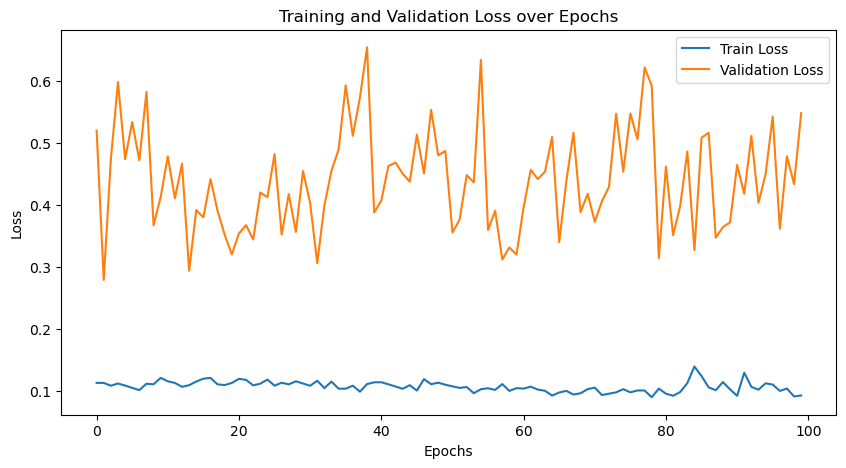

In [28]:
# Create directory MODELS if necessary
# if not os.path.exists(MODELS_dir):
#   os.makedirs(MODELS_dir)

# train_load = DataLoader(dir_path=FOLDER_TRAIN, **model_config, shuffle=True)
# test_load = DataLoader(dir_path=FOLDER_VAL, **model_config, shuffle=False)


#################################################################################################
########## MAIN LOOP
#################################################################################################


NB_BATCH_TRAIN = 13000 * 0.6 / batch_size
NB_BATCH_TEST = 13000 * 0.2 / batch_size
NUMBER_OF_EPOCHS = 100
train_losses = []
val_losses = []

# LOOP OVER EPOCHS
for epoch in range(NUMBER_OF_EPOCHS):
    print(f"Epoch {epoch+1}/{NUMBER_OF_EPOCHS}")

    # stack losses
    list_train_losses, list_val_losses = [], []

    # training dataset
    for x, y in tqdm(data_loader.generate(dataset="train"), desc="Training", leave=False):
        batch = {"x": x, "y": y}
        params, opt_state, loss = update_model(params, opt_state, batch)
        list_train_losses.append(loss)

    # Validation dataset
    for x, y in tqdm(data_loader.generate(dataset="val"), desc="Validation", leave=False):
        batch = {"x": x, "y": y}
        val_loss = loss_fn(params, batch)
        list_val_losses.append(val_loss)

    # Display mean losses for epoch
    train_loss_mean = np.mean(list_train_losses)
    val_loss_mean = np.mean(list_val_losses)
    train_losses.append(train_loss_mean)
    val_losses.append(val_loss_mean)
    print(
        f"Epoch {epoch+1} - Train Loss: {train_loss_mean:.4f}, Validation Loss: {val_loss_mean:.4f}"
    )

print("Training complete.")

# Plot Loss function
plt.figure(figsize=(10, 5))
plt.plot(range(NUMBER_OF_EPOCHS), train_losses, label="Train Loss")
plt.plot(range(NUMBER_OF_EPOCHS), val_losses, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.title("Training and Validation Loss over Epochs")
plt.show()

In [29]:
# Afficher quelques exemples de données d'entraînement et de validation
x_train_example, y_train_example = next(data_loader.generate(dataset="train"))
x_val_example, y_val_example = next(data_loader.generate(dataset="val"))

print("Exemple de données d'entraînement :")
print("Images : ", x_train_example)
print("Paramètres : ", y_train_example)

print("Exemple de données de validation :")
print("Images : ", x_val_example)
print("Paramètres : ", y_val_example)

# Calculer et afficher les pertes pour quelques exemples spécifiques
train_loss_example = current_eval_function(params, {"x": x_train_example, "y": y_train_example})
val_loss_example = current_eval_function(params, {"x": x_val_example, "y": y_val_example})

print(f"Pertes pour un exemple d'entraînement : {train_loss_example}")
print(f"Pertes pour un exemple de validation : {val_loss_example}")

Exemple de données d'entraînement :
Images :  [[[[0.5986937 ]
   [0.47567   ]
   [0.5612    ]
   ...
   [0.38168165]
   [0.50326973]
   [0.47830266]]

  [[0.2151256 ]
   [0.3253491 ]
   [0.36103332]
   ...
   [0.5928353 ]
   [0.4570529 ]
   [0.52882826]]

  [[0.32947066]
   [0.41832978]
   [0.35267702]
   ...
   [0.59073853]
   [0.68331736]
   [0.30119708]]

  ...

  [[0.55538356]
   [0.20946537]
   [0.6214321 ]
   ...
   [0.31161395]
   [0.22659601]
   [0.49152896]]

  [[0.5435936 ]
   [0.35232964]
   [0.38232282]
   ...
   [0.2676363 ]
   [0.40804315]
   [0.4461416 ]]

  [[0.20349377]
   [0.3195844 ]
   [0.50063026]
   ...
   [0.38703096]
   [0.4963404 ]
   [0.35860658]]]


 [[[0.480042  ]
   [0.40221688]
   [0.3090344 ]
   ...
   [0.33769965]
   [0.31080648]
   [0.36806878]]

  [[0.61334187]
   [0.6200219 ]
   [0.38260365]
   ...
   [0.44503626]
   [0.45880872]
   [0.49681935]]

  [[0.36420226]
   [0.47206977]
   [0.39064938]
   ...
   [0.25460345]
   [0.39613077]
   [0.45613128]]



In [ ]:
for epoch in range(NUMBER_OF_EPOCHS):
    print(f"Epoch {epoch+1}/{NUMBER_OF_EPOCHS}")

    # stack losses
    list_train_losses, list_test_losses = []

    # Training dataset
    for x, y in tqdm(data_loader.generate(dataset="train"), desc="Training", leave=False):
        batch = {"x": x, "y": y}
        params, opt_state, loss = current_update_function(params, opt_state, batch)
        list_train_losses.append(loss)

    # Validation dataset
    for x, y in tqdm(data_loader.generate(dataset="val"), desc="Validation", leave=False):
        batch = {"x": x, "y": y}
        test_loss = current_eval_function(params, batch)
        list_test_losses.append(test_loss)

    # Calcul et stockage des pertes moyennes pour l'époque
    train_loss_mean = np.mean(list_train_losses)
    val_loss_mean = np.mean(list_test_losses)
    train_losses.append(train_loss_mean)
    val_losses.append(val_loss_mean)

print("Training complete !")

# Tracer les pertes
plt.figure(figsize=(10, 5))
plt.plot(range(NUMBER_OF_EPOCHS), train_losses, label="Train Loss")
plt.plot(range(NUMBER_OF_EPOCHS), val_losses, label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.title("Training and Validation Loss over Epochs")
plt.show()

In [ ]:
window = 5
train_losses_smoothed = np.convolve(train_losses, np.ones(window) / window, mode="valid")
val_losses_smoothed = np.convolve(val_losses, np.ones(window) / window, mode="valid")
epochs_list_smoothed = epochs_list[(window - 1) :]

# Plot loss function
plt.figure(figsize=(10, 5))
plt.plot(epochs_list, train_losses, label="Training Loss")
plt.plot(epochs_list, val_losses, label="Validation Loss")
plt.plot(epochs_list_smoothed, train_losses_smoothed, label="Avg Training Loss")
plt.plot(epochs_list_smoothed, val_losses_smoothed, label="Avg Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training and Validation Loss with Moving Average")
plt.legend()
plt.xlim(-1, epoch_count)
plt.ylim(0, 0.6)
plt.savefig(PLOTS_dir + "loss_epochs_smoothed_" + case + "_predtrue.png")

In [ ]:
# Read model parameters
with open(MODELS_dir + case + "_complete.pckl", "rb") as handle:
    params_trained = pickle.load(handle)

In [ ]:
dset_test = tfds.load("cosmo_slics", split="train[80%:]", data_dir=IMAGESIMS_dir)
dset_test = dset_test.map(preprocessing)
dset_test = dset_test.batch(batch_size, drop_remainder=True)
dset_test = dset_test.prefetch(-1)
dset_test = dset_test.as_numpy_iterator()

In [ ]:
preds = []
truth = []

# Applying the model
for batch in dset_test:
    # preds.append(model.apply(params, jnp.nan_to_num(batch[0])))
    preds.append(model.apply(params_trained, jnp.nan_to_num(batch[0])))
    truth.append(batch[1])

preds = np.concatenate(preds)
truth = np.concatenate(truth)

In [ ]:
# Create directory PLOTS if necessary
# if not os.path.exists(PLOTS_dir):
#    os.makedirs(PLOTS_dir)

poly_Om = np.polyfit(truth[:, 0], preds[:, 0], 1)
poly_h = np.polyfit(truth[:, 1], preds[:, 1], 1)
poly_w = np.polyfit(truth[:, 2], preds[:, 2], 1)
poly_sig8 = np.polyfit(truth[:, 3], preds[:, 3], 1)

plt.figure(figsize=(11, 11))

#
plt.subplot(221)

t = np.linspace(0.0, 0.6)
plt.plot(t, t, color="k")
plt.fill_between(t, t - 0.05 * 0.3, t + 0.05 * 0.3, color="gray", alpha=0.5)
plt.plot(t, poly_Om[1] + poly_Om[0] * t, color="C1")

plt.scatter(truth[:, 0], preds[:, 0], alpha=0.2, label="$\Omega_{\\rm m}$", color="C1")
plt.xlabel("true")
plt.ylabel("pred")

plt.legend()
plt.title(
    "$\Omega_{\\rm m}^{\\rm pred} = %0.4f \\times \Omega_{\\rm m}^{\\rm true} + %0.4f$"
    % (poly_Om[0], poly_Om[1])
)
plt.ylim(0.0, 0.6)
plt.xlim(0.0, 0.6)

#
plt.subplot(224)

t = np.linspace(0.4, 1.4)
plt.plot(t, t, color="k")
plt.fill_between(t, t - 0.05 * 1.2, t + 0.05 * 1.2, color="gray", alpha=0.5)
plt.plot(t, poly_sig8[1] + poly_sig8[0] * t, color="C3")

plt.scatter(truth[:, 1], preds[:, 1], alpha=0.2, label="$S_8$", color="C3")
plt.xlabel("true")
plt.ylabel("pred")

plt.legend()
plt.title(
    "$S_8^{\\rm pred} = %0.4f \\times S_8^{\\rm true} + %0.4f$" % (poly_sig8[0], poly_sig8[1])
)
# plt.ylim(-2.5,0.0)
# plt.xlim(-2.5,0.0)

#
plt.subplot(222)

t = np.linspace(0.5, 1.0)
plt.plot(t, t, color="k")
plt.fill_between(t, t - 0.05 * 0.75, t + 0.05 * 0.75, color="gray", alpha=0.5)
plt.plot(t, poly_h[1] + poly_h[0] * t, color="C0")

plt.scatter(truth[:, 2], preds[:, 2], alpha=0.2, label="$h$", color="C0")
plt.xlabel("true")
plt.ylabel("pred")

plt.legend()
plt.title("$h^{\\rm pred} = %0.4f \\times h^{\\rm true} + %0.4f$" % (poly_h[0], poly_h[1]))
plt.ylim(0.5, 1.0)
plt.xlim(0.5, 1.0)

#
plt.subplot(223)

t = np.linspace(-2, -0.4)
plt.plot(t, t, color="k")
plt.fill_between(t, t - 0.05 * 0.7, t + 0.05 * 0.7, color="gray", alpha=0.5)
plt.plot(t, poly_w[1] + poly_w[0] * t, color="C2")

plt.scatter(truth[:, 3], preds[:, 3], alpha=0.2, label="$w$", color="C2")
plt.xlabel("true")
plt.ylabel("pred")

plt.legend()
plt.title("$w^{\\rm pred} = %0.4f \\times w^{\\rm true} + %0.4f$" % (poly_w[0], poly_w[1]))
# plt.ylim(0.55,0.85)
# plt.xlim(0.55,0.85)

#
plt.savefig(PLOTS_dir + case + "_predtrue.png")

In [ ]:
# Calculate mean bias for each parameter
mean_bias_Om = np.mean(preds[:, 0] - truth[:, 0])
mean_bias_h = np.mean(preds[:, 1] - truth[:, 1])
mean_bias_w = np.mean(preds[:, 2] - truth[:, 2])
mean_bias_sig8 = np.mean(preds[:, 3] - truth[:, 3])

# Calculate residuals for each parameter
residuals_Om = preds[:, 0] - truth[:, 0]
residuals_h = preds[:, 1] - truth[:, 1]
residuals_w = preds[:, 2] - truth[:, 2]
residuals_sig8 = preds[:, 3] - truth[:, 3]

plt.subplot(233)
plt.axhline(mean_bias_Om, color="red", linestyle="--", label="Mean Bias")
plt.scatter(truth[:, 0], residuals_Om, alpha=0.2, label="Residuals", color="C1")
plt.xlabel("True $\Omega_m$")
plt.ylabel("Residual")
plt.legend()
plt.title("Mean Bias and Residuals for $\Omega_m$")